In [ ]:
import numpy as np
import matplotlib.pyplot as plt

YIELD = 10000 # фотонов/МэВ

In [26]:
class Source:
    def __init__(self, Y=YIELD):
        self.Y = Y
    
    def n_photons(self, E):
        return np.random.poisson(self.Y * E)
    
    def directions(self, N):
        phi = np.random.uniform(0, 2*np.pi, N)
        cos_t = np.random.uniform(-1, 1, N)
        sin_t = np.sqrt(1 - cos_t**2)
        x = sin_t * np.cos(phi)
        y = sin_t * np.sin(phi)
        z = cos_t
        return np.array([x, y, z])
    
    def event(self, E):
        N = self.n_photons(E)
        if N == 0:
            return np.zeros((3, 0))
        return self.directions(N)

In [27]:
src = Source()

E0 = 2.0  # МэВ
dirs = src.event(E0)

print(f"E = {E0} МэВ")
print(f"среднее число фотонов: {src.Y * E0}")
print(f"сгенерировано: {dirs.shape[1]}")
print(f"первые 3 направления:")
print(dirs[:, :3])

E = 2.0 МэВ
среднее число фотонов: 20000.0
сгенерировано: 20250
первые 3 направления:
[[-0.74885392 -0.18930072 -0.26403258]
 [ 0.20076821  0.67166545 -0.38943843]
 [ 0.63159317  0.71626166 -0.88239702]]


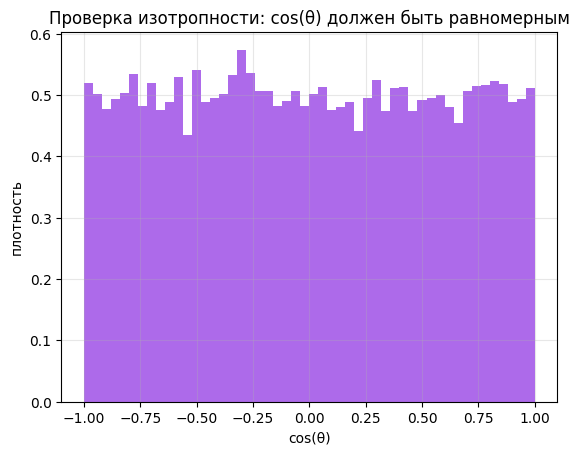

In [28]:
plt.hist(dirs[2], bins=50, density=True, alpha=0.7, color='blueviolet')
plt.xlabel('cos(θ)')
plt.ylabel('плотность')
plt.title('Проверка изотропности: cos(θ) должен быть равномерным')
plt.grid(alpha=0.3)
plt.show()

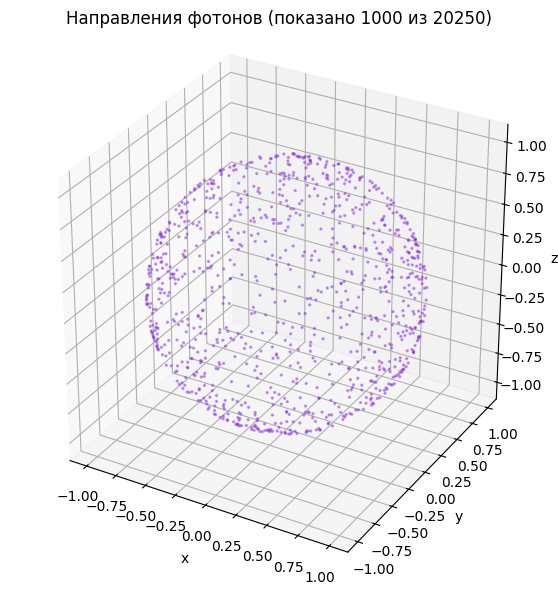

In [29]:
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')

n_show = min(1000, dirs.shape[1])
d = dirs[:, :n_show]

ax.scatter(d[0], d[1], d[2], s=2, alpha=0.4, c='blueviolet')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title(f'Направления фотонов (показано {n_show} из {dirs.shape[1]})')
ax.set_box_aspect([1, 1, 1])
plt.show()

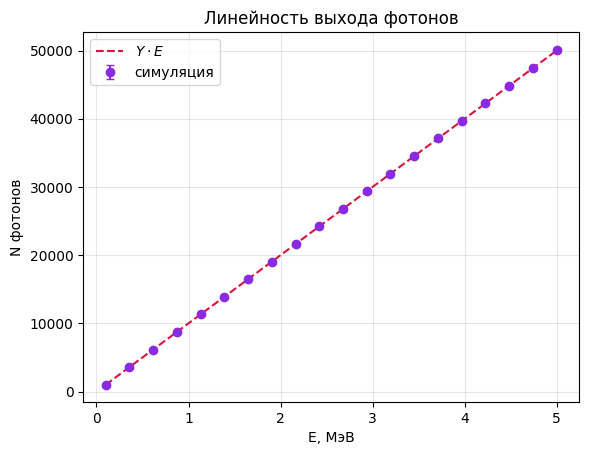

In [30]:
energies = np.linspace(0.1, 5.0, 20)
means = []
stds = []

for E in energies:
    samples = [src.n_photons(E) for _ in range(200)]
    means.append(np.mean(samples))
    stds.append(np.std(samples))

means = np.array(means)
stds = np.array(stds)

plt.errorbar(energies, means, yerr=stds, fmt='o', capsize=3, c='blueviolet', ecolor='blueviolet', label='симуляция')
plt.plot(energies, src.Y * energies, '--', c='crimson', label=r'$Y \cdot E$')

plt.xlabel('E, МэВ')
plt.ylabel('N фотонов')
plt.title('Линейность выхода фотонов')
plt.legend()
plt.grid(alpha=0.3)
plt.show()